In [22]:
#auxiliary functions 
reset()
Zx.<x> = ZZ[]
import numpy as np
def Convolution_in_R(f,g,N):
    return (f*g)%(x^N-1)

def matrix_for_the_lattice(N,q,F):
    H = matrix(N)
    I=identity_matrix(N)

    Zero_Matrix=matrix(N)

    for i in range(N):
        for j in range(N):
            H[i,j] = Convolution_in_R(Zx(F),x^i,N)[j]
       
    B_1=block_matrix([[I,H]])       
    B_2=block_matrix([[Zero_Matrix,q*I]])
    M_NTRU=block_matrix([[B_1],[B_2]])
    return M_NTRU



def LLL_reduction_of_M_NTRU(init_M_NTRU):        
    def fptosage(A):
        n = A.nrows
        C = matrix(n)
        for i in range(n):
            C[i] = list(A[i])
        return C
    import time
    from fpylll import IntegerMatrix,LLL
    start = time.time()
    M_NTRU_fplll = IntegerMatrix.from_matrix(init_M_NTRU)
    LLL.reduction(M_NTRU_fplll, delta =0.99 )
    M_NTRU = fptosage(M_NTRU_fplll)
    print("LLL is done")
    print("time for LLL:"),time.time()-start
    return M_NTRU,M_NTRU_fplll



def find_k_and_P(q):
    for k in range(1,200):
        A,B,C = -(1+k^2), -k^2+2*k*q-1, q*(k-q)
        g = A*x^2+B*x+C
        P = floor( k*q / (k^2+1)  )
        G=g.subs(x=P)
        if G>0:
            A,B,C = -(1+(k-1)^2), -(k-1)^2+2*(k-1)*q-1, q*(k-1-q)
            g = A*x^2+B*x+C
            P = floor( (k-1)*q / ( (k-1)^2+1)  )
            G=g.subs(x=P)
            print(q,":",k-1,P)  
            return k-1,P
        
def is_vfk(Q,N):
    '''
    Q is the Gram-Schimdt matrix of the superbasis
    N is the parameter given when we build ntru_vfk_matrix
    '''
    lst=[]
    x=np.array([Q])
    lst=x[np.nonzero(x)]
    lst=list(lst)
    for i in range(2*N+1):
        if Q[i][i]!=0:
            lst.remove(Q[i][i])
    return all(val <= 0 for val in lst)

def get_superbasis(basis): # basis is a list
    n = len(basis)
    basis = [vector(x) for x in basis]
    superbasis_vector = -sum(basis[i] for i in [0..n-1])
    return [vector(basis[i]) for i in [0..n-1]] + [vector(superbasis_vector)]

def get_qij(superbasis):
    n = len(superbasis)
    Q = [superbasis[i].dot_product(superbasis[j]) for i in range(n) for j in range(n)]
    Q = matrix(n, n, Q)
    return Q

def unimodular(P,N):
    '''
    N,P see the paper (both are positive integer)
    The output is a unimodular matrix of dimension 2N x 2N
    '''
    #upper block
    I=identity_matrix(N)
    Zero_Matrix=matrix(N)
    #lower block
    matrix_P = P*I
    
    B_u = block_matrix([[I,Zero_Matrix]])   
    B_l = block_matrix([[matrix_P,I]])  
    unimod_matrix = block_matrix([[B_u],[B_l]])   
    return unimod_matrix
        
def correction_of_msg(N,m):
    '''
    N: the parameter of NTRU
    m: the message polynomial
    Output: a list of length N with the coefficients of m(x)
    '''
    m_list=m.list()
    if len(m_list)<N:
        diff = N - len(m_list)
        m_list.append(diff*[0])
    return flatten(m_list)
    
def LOG2(x):
    if x==0:
        return 0
    else:
        return log(x,2).n()
        
def bits(L):
    M = []
    for i in range(len(L)):
        M.append(floor(log(L[i],2)) + 1)
    return M
            

 We set, $\Phi_1(x)=x-1$ and  $\Phi_N(x) = D(x)/\Phi_1(x).$<br>
$N$ is prime, and $q\le 16N/3+16$ which is a power of two,
 $D(x)=x^N-1.$<br><br>
`GenKey(seed)`. Takes as input a *seed* and outputs a quadruple
`(pk,sk)`=$({\textbf h},({\textbf f},{\textbf f}_3,{\textbf h}_q)).$\
\
`1.` $(f(x),g(x))\xleftarrow{\$} {\mathcal{L}}_f\times {\mathcal{L}}_g$
\# `here we use the seed`\
`2.` $f_q(x)\leftarrow f^{-1}(x)\mod{(q,\Phi_N(x))}$ \# $\Phi_N(x)=x^{N-1}+\cdots x+1$\
`3.` $f_3(x)\leftarrow f^{-1}(x)\mod{(3,\Phi_N(x))}$\
`4.` $h(x) \leftarrow 3g(x)*f_q(x)\mod{(q,D(x))}$  $\# D(x)=x^N-1$\
`5.` $h_q(x) \leftarrow h^{-1}(x)\mod{(q,\Phi_N(x))}$ \
`6.` ${\mathbb{S}} \xleftarrow{\$} \{0,1\}^{256}$ \
`7.` **return**
 $(pk,sk)=({\textbf h},({\textbf f},{\textbf f}_3,{\textbf h}_q,{\mathbb{S}}))$

We also need to define the sample sets.<br>
With ${\mathcal{T}}_a$ we denote the set of **ternary** polynomials of
${\mathcal{R}}={\mathbb{Z}}[z]/(x^a-1)$ with degree at most $a-1$ and
$\mathcal{T}_a(d_1,d_2)\subset {\mathcal{T}}_{a}$ consists from elements
of ${\mathcal{T}}_{a}$ with $d_1$ coefficients equal to $1$ and $d_2$
equal to $-1.$ Furthermore, with
${\mathcal{T}}_a(w), w\in{\mathbb{Z}}_{>0}$ we denote the ternary
polynomials which have $w$ non-zero coefficients. We also have four sample spaces,
${\mathcal{L}}_f, {\mathcal{L}}_g, {\mathcal{L}}_r,$ and ${\mathcal{L}}_m.$\
$-$ ${\mathcal{L}}_m={\mathcal{L}}_g=
{\mathcal{T}}_{N-2}(\frac{q}{16}-1,\frac{q}{16}-1),$\
$-$ ${\mathcal{L}}_f={\mathcal{L}}_r={\mathcal{T}}_{N-2}.$


# Key Generation/Encrypt/Decrypt

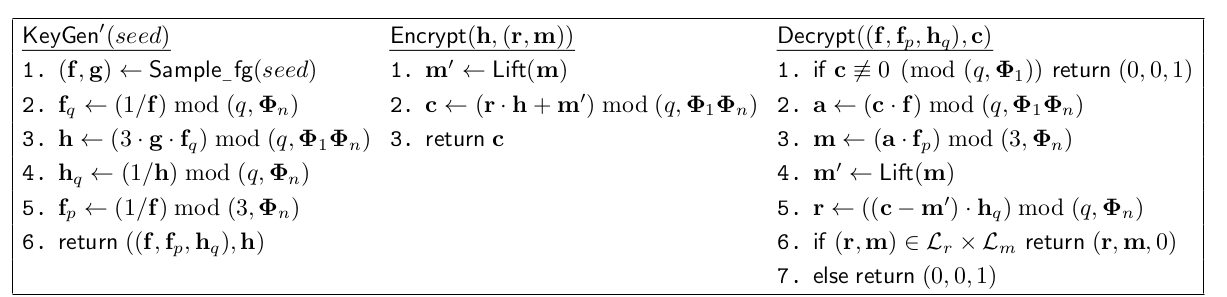

In [23]:
def random32(): return randrange(-2^31,2^31)        # a random integer in -2^31 and 2^31

def randomrange3():  
    ''' 
    generate a random integer in {0, 1, 2} 
    by utilizing a 32-bit random number generator : random32()
    '''
    return ((random32() & 0x3fffffff) * 3) >> 30


# we generate ternary polynomials of degre at most with d1 one and d2 minus one
def T(d1,d2,N):
    import random
    Zx.<x> = ZZ[]    
    a = d1*[1]
    b = d2*[-1]
    c = (N+1-d1-d2)*[0] #the length must be N+1 to get a polynomial of degree at most N
    L = flatten([a,b,c])
    random.shuffle(L) 
    return L,Zx(L)
    

def CenterLift(f,q,N):    
    f_balanced = list(   ((f[i]+q//2)%q) -q//2  for i in range(N))
    return Zx(f_balanced)

def reduce_mod_PhiN_and_modq(f):
    return Zx(S(f).lift())%q

def reduce_mod_DN_and_modq(f): # if f=G*F then we get the multiplication of G and F in R/(q,x^N-1) 
    return Zx(R(f).lift())%q

def Convolution_in_S_q(f,g,N,q): 
    PhiN=sum(x^i for i in [0..N-1])
    h = (f*g)%(PhiN)
    return  Zx(h)%q  

def Convolution_in_S(f,g,N):
    PhiN=sum(x^i for i in [0..N-1])
    h = (f*g)%(PhiN)
    #h1 = list( (h[i]%q)   for i in range(N) )
    return  Zx(h) 

def Invertmodprime_and_phiN(f,p,N):        #p must be prime
    phiN = sum(x^i for i in [0..N-1])
    if is_prime(p)==False:
        return "error"
    T = Zx.change_ring(Integers(p)).quotient(PhiN)
    return Zx(lift(1/T(f)))

def invert_mod_2_and_phiN(f):
    return Zx( (1/S2(f)).lift())

def Invertmodpowerofprime_mod_PhiN(f,Q,e,N): # Q prime, e: exponent
    F = invert_mod_2_and_phiN(f)
    if e == 1:      
        return F
    temp_exponent = 2
    while e>0:
        temp = Convolution_in_S(F,f,N)
        F = Convolution_in_S_q(F,2-temp,N,Q^temp_exponent)
        e = floor(e/2)
        temp_exponent = 2*temp_exponent
    return F

def Invert_mod3_and_PhiN(f):
    T = 1/S3(f)
    return T    

def private_keys(N):
    # for L_g we choose d=q/16-1
    # for L_f we choose T_{N-2}
    while True:
        f = Zx([randomrange3()-1 for i in range(N-1)])
        if S3(f).is_unit(): break
    d=q/16-1;g = T(d,d,N-2)
    return f,g[1]

def gen_keys(N,q): 
    # N,p primes, e exponent 
    # q = (base)^(exponent)
    f,g=private_keys(N);
    # We set D = x^N-1 and phiN=D/(x-1)
    base_of_q = 2
    exponent  = int(log(q,2))
    try:
        fq=Invertmodpowerofprime_mod_PhiN(f,base_of_q,exponent,N)
    except ZeroDivisionError:
        print("Oops! there is not inverse of f in R_{0}".format(q))
        return _,_,_,_,_,_
    try:
        f3 = Invert_mod3_and_PhiN(f)
    except ZeroDivisionError:
        print("Oops! there is not inverse of f in R_{0}".format(3))
        return _,_,_,_,_,_
    fq = fq%q
    h   = 3*reduce_mod_DN_and_modq(fq * g); # public key, we work mod<q,x^N-1>
    try: 
        hq=Invertmodpowerofprime_mod_PhiN(h,base_of_q,exponent,N)
    except ZeroDivisionError:
        print("Oops! there is not inverse of h in R_{0}".format(q))
        return
    hq = hq%q
    #print("public key\nh=3g/f:{0} \nprivate key\nf:{1}\nf3:{2}\nhq:{3}\ng:{4}".format(h,f,f3,hq,g))
    return h,f,Zx(f3.lift()),hq,g,fq

### Encryption
def enc(N,q,msg,h):
    r = Zx([randomrange3()-1 for i in range(N-1)]) #ephemeral key, a ternary of degree <=N-2
    ### Encryption
    ct1=reduce_mod_DN_and_modq(h*r)  # mod <q,x^N-1>
    ct = reduce_mod_DN_and_modq(ct1 + msg)   # mod <q,x^N-1>
    #print("r={0}\nct1={1}\nmsg={2}\nct={3}".format(r,ct1,msg,ct))
    return ct,r

def decryption(ct,f,m):
    a=reduce_mod_DN_and_modq(ct * f)
    a=CenterLift(a,q,N)
    if S3(a*f3)==S3(m):
        print("decryption OK")
    return Zx(S3(a*f3).lift())


In [24]:
#parameters for NTRU-HPS KEM
# returns N,q
def ntruhps(x):
    if x==1:
        return 509,2048 #ntruhps2048509
    if x==2:
        return 677,2048
    if x==3:
        return 821,4096
N,q=ntruhps(1)

In [25]:
N,q=13,2^6 # if you want to define other parameters
print("N,q=",N,q)
print(q/16 - 1<=2*N/3)
D,PhiN,Phi1=x^N-1,sum(x^i for i in [0..N-1]),x-1

Zx.<x> = ZZ[]
R.<xN> = Zx.quotient(D)
S.<XN> = Zx.quotient(PhiN)

F3 = GF(3); 
F3x.<x3> = F3[]; 
Phi3N = sum(x3^i for i in [0..N-1])
S3.<X3> = F3x.quotient(Phi3N)

F2 = GF(2); F2x.<x2> = F2[]
Phi2N=sum(x2^i for i in [0..N-1])
S2.<X2> = F2x.quotient(Phi2N)


N,q= 13 64
True


In [26]:
h,f,f3,hq,g,fq = gen_keys(N=N,q=q)

In [27]:
# sanity check
msg = T(q/16-1,q/16-1,N-2) # Since we want messages of weight q/8-2.
ct,r=enc(N,q,msg[1],h)
m = msg[1]
_=decryption(ct,f,m)

decryption OK


# The Attack<br>
The first step is to define the matrix 
$$ 
	M_k=
    \left[\begin{array}{c|c}
	I_N & -kI_N  \\
	\hline
	{\textbf 0}_N & qI_N   \\
	\end{array}\right].
    $$
Since it is VFK lattice we have a polynomial algorithm for the CVP, but we need a superbasis.<br>
 The previous matrix does not provide us with a superbasis. We shall need the suitable uniary matrix in 
 order to find it.<br> The following code does also this.

In [28]:
def choice_of_E(N,q,kappa,r,h,Range,m):  
    '''
    Input
    -----
    N,q   : initial parameters of the system
    r     : the nonce polynomial
    h     : the public key polynomial
    ct    : the ciphertext
    Range : a positive integer
    
    output
    ------
    (a list) corresponding to the guessing vector E such that ||E_{i+N} - u_i||<Range
    ''' 
    
    def find_integer_with_min_distance(a, b, c):
        min_distance = float('inf')  # Initialize with positive infinity.
        integer_with_min_distance = None

        # Iterate through integers starting from the minimum of a, b, and c to the maximum.
        for x in range(min(a, b, c), max(a, b, c) + 1):
            #distance = max(abs(a - x) , abs(b - x) ,abs(c - x))
            #distance = (a - x)**2 + (b - x)**2 + (c - x)**2
            distance = abs(a - x) + abs(b - x) + abs(c - x)

            # Check if the current distance is smaller than the minimum distance.
            if distance < min_distance:
                min_distance = distance
                integer_with_min_distance = x

        return integer_with_min_distance

    
    b1=kappa*ct # the polynomial k*ct(x) in R/q, is known
    b=b1
    Blist=b.coefficients(sparse=False)
    
    def pick_for_E(N,kappa,ct,Blist):
        B = []
        S = []
        my_set = []
        for i in range(N):
            #my_set = [kappa-Blist[i],-Blist[i],-kappa-Blist[i]]
            #z=floor(sum(my_set)/3)
            z=find_integer_with_min_distance(1-Blist[i]/kappa, -Blist[i]/kappa, -1-Blist[i]/kappa)
            #z=choice([1-Blist[i]/kappa, -Blist[i]/kappa, -1-Blist[i]/kappa])
            #min_=min([1-Blist[i]/kappa, -Blist[i]/kappa, -1-Blist[i]/kappa])
            #max_=max([1-Blist[i]/kappa, -Blist[i]/kappa, -1-Blist[i]/kappa])
            #z=randint(min_,max_)
            #B.append(kappa*z+2)
            B.append(kappa*z)
            S.append(0)
        return B,S

    less_bad_choice,S = pick_for_E(N,kappa,ct,Blist)
    
    temp_u = []
    temp_msg=[]
    temp_msg1=[]
    hr = reduce_mod_DN_and_modq(h*r)
    u  = -kappa*hr     # u : the unknown vector u such that u(x)=-kappa(h*r)
    u_list = u.list()  # convert to list    
    u_vector = vector(u_list)     # write u as sage vector

    
    #temp  = u_vector  + vector([randint(-Range,Range) for i in range(N)])
    #E = [0]*N + list(temp);
    #temp_msg = vector([randint(-1,1) for i in range(N)])
    temp_msg1 = T(q/16-1,q/16-1,N-2)
    temp_msg = correction_of_msg(N,temp_msg1[1])
    #temp_msg = temp_msg1[0]
    
    temp_u =[-Blist[i] for i in range(floor(N/2))] + [-kappa-Blist[i] for i in range(floor(N/4))] + \
    [kappa-Blist[i] for i in range(floor(N/4)+1)]
    random.shuffle(temp_u)
    #print(len(temp_u))
    #temp_u = less_bad_choice
    #E = list(temp_msg) + list(u_vector)[0:floor(0.9*N)] + list(temp_u)[floor(0.9*N):N]
    E = list(temp_msg) + list(temp_u)
    #print((u_vector-vector(temp)).norm().n())
    msg_list = correction_of_msg(N,m) 
    Real_list = msg_list + u_list # the sum here is the concatenation of the two lists 
    #print("real list:",Real_list,len(Real_list))
    #print("E:",E,len(E))
    print("|real-E|",( vector(Real_list)-vector(E) ).norm().n())
    return E

def target_vector(N,E,kappa,ct):
    '''
    Input
    -----
    N   : initial param of NTRU-prime, N=p
    E   : the guessing vector, from the oracle
    ct  : the ciphertext
    
    Output
    ------
    the target vector of the form
    (0_N,b1+E1,...,bN+EN)
    '''  
    b1=kappa*ct # the polynomial k*ct(x) in R/q
    b=b1
    Blist=b.coefficients(sparse=False)
    if len(Blist)==N:
        t = vector(N*[0] + Blist) + vector(E)
    return t # the target vector t = (0_N,b) + E    

In [30]:
def init_attack_2(N,q,kappa,P):
    alpha_vector_vfk = [-kappa] + [0 for i in range(N-1)] 
    A = Zx(alpha_vector_vfk)
    M_k = matrix_for_the_lattice(N,q,A)
    M_NTRU_VFK=unimodular(P,N)*M_k
    # from paper: remark 5.1
    r = - ((kappa*P + kappa - q)*kappa + P + 1)
    s = (kappa*P + kappa - q)*(q - kappa*P ) - (P + 1)*P
    t = (kappa*P-q)*kappa + P
    diag1 = N * ( (1 + P )^2 + ( kappa*(P + 1) - q)^2 )
    diag2 = 1+kappa^2
    #print("r,s,t:",r,s,t)
    basis = M_NTRU_VFK.rows()
    super_basis=get_superbasis(basis)
    Q=get_qij(super_basis)
    print("is VFK?",is_vfk(Q,N))
    return Q,M_NTRU_VFK,M_k,super_basis
#kappa,Q,M_NTRU_VFK,M_k,super_basis=init_attack(N,q)
kappa,P=11,5
Q,M_NTRU_VFK,M_k,super_basis=init_attack_2(N,q,kappa,P)

is VFK? True
